In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

Reading lesions, a_eendpt from 1053

In [3]:

lesions=pd.read_csv("C:\\Users\\Admin\\Downloads\\1053_lesion.csv")

In [4]:
lesions.shape

(30153, 89)

In [5]:
lesions.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,TRTFREQ,TRTCD,TRT,ATRTCD,ATRT,CHEMOCD,CHEMO,CHEMOICD,CHEMOI,ACHEMOCD,ACHEMO,ACHEMMCD,ACHEMM,FCHEMOCD,FCHEMO,B_LESNM,B_LESNMT,B_LESNMN,B_METANM,B_METACT,BMETACTI,FSTOXDS,FSTIRDS,DURSURG,PRADJYN,PRADJICD,PRADJI,B_LDHYN,B_ECOGCD,B_ECOG,BECOGICD,B_ECOGI,DIAGTYCD,DIAGTYPE,DIAGICD,DIAGI,RESPSTAT,EVALITT,EVALPP,PDADEN,PDICSIG,PDICMIS,PDPROMED,PDYN,KRASCD,KRAS,EVALKEA,EVALKSA,EVALKUE,DOSREFDY,DOSREFWK,VISITCD,VISIT,PHASECD,PHASE,LSTYPECD,LSTYPE,LSCATCD,LSCAT,LSNO,LSSITECD,LSSITE,LSPROCCD,LSPROC,LSRAWCD,LSRAW,LSNEW,LSNEWANY,LSNUM,LSLD,LSSLD,LSSLDPCH,LSSLDPCN,LSRESPCD,LSRESP,LSEXAMNO,LSIMAGNO,LSRI,TRTDUR
0,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,81.144198,NaN,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-8.0,-2.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,NaN,NaN,NaN,NaN,NaN,46.0,CT pelvis,NaN,NaN,NaN,N,NaN,NaN,51.0,NaN,NaN,NaN,NaN,3.0,NaN,7.0,685.0
1,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,81.144198,NaN,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-8.0,-2.0,SCR,Screening,10.0,Pre-treatment,2.0,Local,1.0,Target lesion,1.0,812.0,Lung,23.0,Spiral CT,NaN,NaN,N,N,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,685.0
2,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,81.144198,NaN,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-8.0,-2.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,2.0,Non-target lesion,202.0,811.0,Liver,41.0,CT abdomen,262.0,Liver mass/nodule,N,N,NaN,NaN,51.0,NaN,NaN,NaN,NaN,2.0,16,7.0,685.0
3,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,81.144198,NaN,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-2.0,-1.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,1.0,Target lesion,1.0,897.0,Pulmonary,40.0,CT chest,257.0,Right Lung mass/nodule,N,N,NaN,13.0,51.0,NaN,NaN,NaN,NaN,1.0,10,5.0,685.0
4,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,81.144198,NaN,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-2.0,-1.0,SCR,Screening,10.0,Pre-treatment,2.0,Local,2.0,Non-target lesion,1.0,812.0,Lung,23.0,Spiral CT,NaN,NaN,N,N,99.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,685.0


In [6]:
lesions = lesions.drop_duplicates(keep='first')

In [7]:
lesions.shape

(30153, 89)

In [8]:
lesions.isnull().sum()

STUDYID         0
SITEID          0
SUBJID          0
AGE             0
SEXCD           0
SEX             0
RACCATCD        0
RACCAT          0
TRTDOSE         0
TRTFRQCD        0
TRTFREQ         0
TRTCD           0
TRT             0
ATRTCD          0
ATRT            0
CHEMOCD         0
CHEMO           0
CHEMOICD        0
CHEMOI          0
ACHEMOCD       11
ACHEMO         11
ACHEMMCD        0
ACHEMM          0
FCHEMOCD      163
FCHEMO        163
B_LESNM         0
B_LESNMT        0
B_LESNMN        0
B_METANM        0
B_METACT        0
BMETACTI        0
FSTOXDS      5962
FSTIRDS     24323
DURSURG      2697
PRADJYN         0
PRADJICD        0
PRADJI          0
B_LDHYN       564
B_ECOGCD        0
B_ECOG          0
BECOGICD        0
B_ECOGI         0
DIAGTYCD        0
DIAGTYPE        0
DIAGICD         0
DIAGI           0
RESPSTAT     2234
EVALITT         0
EVALPP          0
PDADEN          0
PDICSIG         0
PDICMIS         0
PDPROMED        0
PDYN            0
KRASCD       1799
KRAS      

In [9]:
null_counts = lesions.isnull().sum()

In [10]:
columns_to_drop = null_counts[null_counts > 4500].index

In [11]:
lesions = lesions.drop(columns=columns_to_drop)

In [12]:
columns_to_drop_rows = null_counts[null_counts <= 4500].index

In [13]:
lesions = lesions.dropna(subset=columns_to_drop_rows)

In [14]:
lesions.isnull().sum()

STUDYID     0
SITEID      0
SUBJID      0
AGE         0
SEXCD       0
SEX         0
RACCATCD    0
RACCAT      0
TRTDOSE     0
TRTFRQCD    0
TRTFREQ     0
TRTCD       0
TRT         0
ATRTCD      0
ATRT        0
CHEMOCD     0
CHEMO       0
CHEMOICD    0
CHEMOI      0
ACHEMOCD    0
ACHEMO      0
ACHEMMCD    0
ACHEMM      0
FCHEMOCD    0
FCHEMO      0
B_LESNM     0
B_LESNMT    0
B_LESNMN    0
B_METANM    0
B_METACT    0
BMETACTI    0
DURSURG     0
PRADJYN     0
PRADJICD    0
PRADJI      0
B_LDHYN     0
B_ECOGCD    0
B_ECOG      0
BECOGICD    0
B_ECOGI     0
DIAGTYCD    0
DIAGTYPE    0
DIAGICD     0
DIAGI       0
RESPSTAT    0
EVALITT     0
EVALPP      0
PDADEN      0
PDICSIG     0
PDICMIS     0
PDPROMED    0
PDYN        0
KRASCD      0
KRAS        0
EVALKEA     0
EVALKSA     0
EVALKUE     0
DOSREFDY    0
DOSREFWK    0
VISITCD     0
VISIT       0
PHASECD     0
PHASE       0
LSTYPECD    0
LSTYPE      0
LSCATCD     0
LSCAT       0
LSNO        0
LSSITECD    0
LSSITE      0
LSPROCCD    0
LSPROC

In [15]:
a_eendpt = pd.read_csv("c:\\Users\\Admin\\Downloads\\a_eendpt.csv")

In [16]:
a_eendpt = a_eendpt.drop_duplicates(keep='first')

In [17]:
a_eendpt.shape

(842, 122)

In [18]:
a_eendpt.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,TRTFREQ,TRTCD,TRT,ATRTCD,ATRT,CHEMOCD,CHEMO,CHEMOICD,CHEMOI,ACHEMOCD,ACHEMO,ACHEMMCD,ACHEMM,FCHEMOCD,FCHEMO,B_LESNM,B_LESNMT,B_LESNMN,B_METANM,B_METACT,BMETACTI,FSTOXDS,FSTIRDS,DURSURG,PRADJYN,PRADJICD,PRADJI,B_LDHYN,B_ECOGCD,B_ECOG,BECOGICD,B_ECOGI,DIAGTYCD,DIAGTYPE,DIAGICD,DIAGI,RESPSTAT,EVALITT,EVALPP,PDADEN,PDICSIG,PDICMIS,PDPROMED,PDYN,KRASCD,KRAS,EVALKEA,EVALKSA,EVALKUE,R12LR,R12LRCA,R12LRSD,R12CR,R12CRCA,R12CRSD,ROSCR,ROSLR,ROSLRCA,RLR,RCR,RDURLR,RDURWLR,RDURLRC,RDURCR,RDURWCR,RDURCRC,RDYLR,RDYCR,PFSDYCR,PFSMTCR,PFSCR,PFSDYLR,PFSMTLR,PFSLR,PDDYCR,PDCR,PDMTCR,PDDYLR,PDMTLR,PDLR,DTHDY,DTHMT,DTH,TFAILDY,TFAILMT,TFAIL,SDDURLR,SDDURWLR,SDDURLRC,SDDURCR,SDDURWCR,SDDURCRC,DTH30,DTHDY30,DTHMT30,PDCR30,PDDYCR30,PDMTCR30,PDLR30,PDDYLR30,PDMTLR30,PFSCR30,PFSDCR30,PFSMCR30,PFSLR30,PFSDLR30,PFSMLR30,PDCRND,PDDYCRND,PDMTCRND,TRTDUR,LASTCRDY
0,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,81.144198,NaN,45.573770,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,0.0,NaN,0.0,0.0,NaN,0.0,1.0,1.0,PR,1.0,1.0,568.0,81.142857,1.0,568.0,81.142857,1.0,101.0,101.0,668.0,21.946612,1.0,668.0,21.946612,1.0,668.0,1.0,21.946612,668.0,21.946612,1.0,1507.0,49.511294,0.0,668.0,21.946612,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,719.0,23.622177,1.0,668.0,21.946612,1.0,668.0,21.946612,1.0,668.0,21.946612,1.0,668.0,21.946612,1.0,668.0,21.946612,685.0,618.0
1,20040249,101,249101002,72.0,M,Male,1.0,White or Caucasian,0.0,Q2WK,Every 2 weeks,12.0,bevacizumab with chemotherapy,12.0,bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,101.0,2.0,99.0,2.0,>1,>1,90.712273,NaN,44.065574,N,0.0,N,N,1.0,Symptoms but ambulatory,1.0,Symptoms but ambulatory,1251.0,Colon,1251.0,Colon,N,Y,Y,N,N,N,N,N,2.0,Mutant,Y,Y,N,0.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,SD,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,315.0,10.349076,1.0,369.0,12.123203,1.0,315.0,1.0,10.349076,369.0,12.123203,1.0,482.0,15.835729,1.0,369.0,12.123203,1.0,369.0,52.714286,1.0,315.0,45.000000,1.0,0.0,399.0,13.108830,1.0,315.0,10.349076,1.0,369.0,12.123203,1.0,315.0,10.349076,1.0,369.0,12.123203,1.0,315.0,10.349076,365.0,162.0
2,20040249,101,249101003,78.0,M,Male,1.0,White or Caucasian,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,101.0,2.0,99.0,2.0,>1,1,84.244651,NaN,0.000000,N,0.0,N,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,88.0,Failed,N,N,Y,1.0,PR,1.0,0.0,SD,1.0,1.0,1.0,PR,1.0,1.0,113.0,16.142857,0.0,1.0,0.142857,0.0,84.0,185.0,196.0,6.439425,1.0,196.0,6.439425,1.0,185.0,0.0,6.078029,196.0,6.439425,0.0,196.0,6.439425,1.0,191.0,6.275154,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,196.0,6.439425,0.0,185.0,6.078029,0.0,196.0,6.439425,1.0,196.0,6.439425,1.0,196.0,6.439425,0.0,185.0,6.078029,166.0,185.0
3,20040249,101,249101005,66.0,F,Female,2.0,Black or African American,0.0,Q2WK,Every 2 weeks,12.0,bevacizumab with chemotherapy,12.0,bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,101.0,2.0,99.0,2.0,>1,>1,84.943334,NaN,-0.032787,N,0.0,N,N,1.0,Symptoms but ambulatory,1.0,Symptoms but ambulatory,1251.0,Colon,1251.0,Colon,N,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,0.0,SD,1.0,0.0,SD,1.0,0.0,0.0,SD,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.0,3.219713,1.0,98.0,3.219713,1.0,86.0,0.0,2.825462,98.0,3.219713,0.0,98.0,3.219713,1.0,98.0,3.219713,1.0,98.0,14.000000,0.0,86.0,12.285714,0.0,1.0,98.0,3.219713,0.0,86.0,2.825462,0.0,98.0,3.219713,1.0,98.0,3.219713,1.0,98.0,3.219713,0.0,86.0,2

In [19]:
a_eendpt.isnull().sum()

STUDYID       0
SITEID        0
SUBJID        0
AGE           0
SEXCD         0
SEX           0
RACCATCD      0
RACCAT        0
TRTDOSE       0
TRTFRQCD      0
TRTFREQ       0
TRTCD         0
TRT           0
ATRTCD        0
ATRT          0
CHEMOCD       0
CHEMO         0
CHEMOICD      0
CHEMOI        0
ACHEMOCD      2
ACHEMO        2
ACHEMMCD      0
ACHEMM        0
FCHEMOCD     20
FCHEMO       20
B_LESNM       0
B_LESNMT      0
B_LESNMN      0
B_METANM      0
B_METACT      0
BMETACTI      0
FSTOXDS     185
FSTIRDS     676
DURSURG      83
PRADJYN       0
PRADJICD      0
PRADJI        0
B_LDHYN      32
B_ECOGCD      0
B_ECOG        0
BECOGICD      0
B_ECOGI       0
DIAGTYCD      0
DIAGTYPE      0
DIAGICD       0
DIAGI         0
RESPSTAT    134
EVALITT       0
EVALPP        0
PDADEN        0
PDICSIG       0
PDICMIS       0
PDPROMED      0
PDYN          0
KRASCD       63
KRAS         63
EVALKEA       0
EVALKSA       0
EVALKUE       0
R12LR         0
R12LRCA     160
R12LRSD       0
R12CR   

In [20]:
a_eendpt_reduced = a_eendpt[['SUBJID','PFSCR']]

In [21]:
a_eendpt_reduced.head()

,SUBJID,PFSCR
0,249101001,1.0
1,249101002,1.0
2,249101003,1.0
3,249101005,1.0
4,249101006,1.0


In [22]:
df = lesions.merge(a_eendpt_reduced,on=['SUBJID'],how='left')

In [23]:
df.head()

,STUDYID,SITEID,SUBJID,AGE,SEXCD,SEX,RACCATCD,RACCAT,TRTDOSE,TRTFRQCD,TRTFREQ,TRTCD,TRT,ATRTCD,ATRT,CHEMOCD,CHEMO,CHEMOICD,CHEMOI,ACHEMOCD,ACHEMO,ACHEMMCD,ACHEMM,FCHEMOCD,FCHEMO,B_LESNM,B_LESNMT,B_LESNMN,B_METANM,B_METACT,BMETACTI,DURSURG,PRADJYN,PRADJICD,PRADJI,B_LDHYN,B_ECOGCD,B_ECOG,BECOGICD,B_ECOGI,DIAGTYCD,DIAGTYPE,DIAGICD,DIAGI,RESPSTAT,EVALITT,EVALPP,PDADEN,PDICSIG,PDICMIS,PDPROMED,PDYN,KRASCD,KRAS,EVALKEA,EVALKSA,EVALKUE,DOSREFDY,DOSREFWK,VISITCD,VISIT,PHASECD,PHASE,LSTYPECD,LSTYPE,LSCATCD,LSCAT,LSNO,LSSITECD,LSSITE,LSPROCCD,LSPROC,LSNEW,LSNEWANY,LSSLD,LSEXAMNO,LSRI,TRTDUR,PFSCR
0,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-8.0,-2.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,2.0,Non-target lesion,202.0,811.0,Liver,41.0,CT abdomen,N,N,51.0,2.0,7.0,685.0,1.0
1,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-2.0,-1.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,1.0,Target lesion,1.0,897.0,Pulmonary,40.0,CT chest,N,N,51.0,1.0,5.0,685.0,1.0
2,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-2.0,-1.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,1.0,Target lesion,2.0,897.0,Pulmonary,40.0,CT chest,N,N,51.0,1.0,5.0,685.0,1.0
3,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-2.0,-1.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,1.0,Target lesion,3.0,897.0,Pulmonary,40.0,CT chest,N,N,51.0,1.0,5.0,685.0,1.0
4,20040249,101,249101001,67.0,F,Female,2.0,Black or African American,6.0,Q2WK,Every 2 weeks,11.0,panit. plus bevacizumab with chemotherapy,11.0,panit. plus bevacizumab with chemotherapy,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,78.0,Oxaliplatin,100.0,1.0,99.0,1.0,1,1,45.57377,Y,1.0,Y,N,0.0,Fully active,0.0,Fully active,1251.0,Colon,1251.0,Colon,Y,Y,Y,N,N,N,N,N,1.0,Wild-type,Y,Y,N,-2.0,-1.0,SCR,Screening,10.0,Pre-treatment,1.0,Central,1.0,Target lesion,4.0,897.0,Pulmonary,40.0,CT chest,N,N,51.0,1.0,5.0,685.0,1.0


In [24]:
df.shape

(17814, 79)

In [25]:
df.columns

Index(['STUDYID', 'SITEID', 'SUBJID', 'AGE', 'SEXCD', 'SEX', 'RACCATCD', 'RACCAT', 'TRTDOSE', 'TRTFRQCD', 'TRTFREQ', 'TRTCD', 'TRT', 'ATRTCD', 'ATRT', 'CHEMOCD', 'CHEMO', 'CHEMOICD', 'CHEMOI', 'ACHEMOCD', 'ACHEMO', 'ACHEMMCD', 'ACHEMM', 'FCHEMOCD', 'FCHEMO', 'B_LESNM', 'B_LESNMT', 'B_LESNMN', 'B_METANM', 'B_METACT', 'BMETACTI', 'DURSURG', 'PRADJYN', 'PRADJICD', 'PRADJI', 'B_LDHYN', 'B_ECOGCD', 'B_ECOG', 'BECOGICD', 'B_ECOGI', 'DIAGTYCD', 'DIAGTYPE', 'DIAGICD', 'DIAGI', 'RESPSTAT', 'EVALITT', 'EVALPP', 'PDADEN', 'PDICSIG', 'PDICMIS', 'PDPROMED', 'PDYN', 'KRASCD', 'KRAS', 'EVALKEA', 'EVALKSA', 'EVALKUE', 'DOSREFDY', 'DOSREFWK', 'VISITCD', 'VISIT', 'PHASECD', 'PHASE', 'LSTYPECD', 'LSTYPE', 'LSCATCD', 'LSCAT', 'LSNO', 'LSSITECD', 'LSSITE', 'LSPROCCD', 'LSPROC', 'LSNEW', 'LSNEWANY', 'LSSLD', 'LSEXAMNO', 'LSRI', 'TRTDUR', 'PFSCR'], dtype='object')

In [26]:
df = df[['SUBJID','PFSCR','LSSLD','LSNEWANY']]

In [27]:
df.head()

,SUBJID,PFSCR,LSSLD,LSNEWANY
0,249101001,1.0,51.0,N
1,249101001,1.0,51.0,N
2,249101001,1.0,51.0,N
3,249101001,1.0,51.0,N
4,249101001,1.0,51.0,N


In [28]:
new_lesion_1186_1186 = pd.read_csv("C:\\Users\\Admin\\Downloads\\new_lesion_1186_1183.csv")

In [29]:
new_lesion_1186_1186.head()

,LBSTRESN,PFSCR,LSSLD,LSNEWANY,LBTEST_Carcinoembryonic Antigen,LBTEST_Lactate Dehydrogenase
0,135.910100,1.0,99.000000,0,126.0,126.0
1,135.910100,1.0,99.000000,1,126.0,126.0
2,153.863690,1.0,284.521127,0,1414.0,1414.0
3,112.913064,1.0,44.071429,0,784.0,784.0
4,190.772448,1.0,206.210526,0,198.0,198.0


## Synthetic Data Generation

In [30]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

In [31]:
df['LSNEWANY'] = df['LSNEWANY'].map({'N': 0, 'Y': 1})

In [32]:
X = new_lesion_1186_1186[['PFSCR', 'LSSLD', 'LSNEWANY']]
y_lbstresn = new_lesion_1186_1186['LBSTRESN']
y_carcinoembryonic_antigen = new_lesion_1186_1186['LBTEST_Carcinoembryonic Antigen']

In [33]:
rf_lbstresn = RandomForestRegressor(n_estimators=100, random_state=42)
rf_carcinoembryonic_antigen = RandomForestRegressor(n_estimators=100, random_state=42)

In [34]:
rf_lbstresn.fit(X, y_lbstresn)
rf_carcinoembryonic_antigen.fit(X, y_carcinoembryonic_antigen)

RandomForestRegressor(random_state=42)

In [35]:
# Features from df2 for prediction
X_df = df[['PFSCR', 'LSSLD', 'LSNEWANY']]

# Generate synthetic features
df['LBSTRESN'] = rf_lbstresn.predict(X_df)
df['LBTEST_Carcinoembryonic Antigen'] = rf_carcinoembryonic_antigen.predict(X_df)

In [36]:
df.to_csv('1053_final_syn.csv', index=False)

## Using XGBoost

In [37]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

In [38]:
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3],
    'n_estimators': [100, 200, 300],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'gamma': [0, 0.1, 0.3]
}

In [39]:
model_LBSTRESN = xgb.XGBRegressor(objective='reg:squarederror')

grid_search_LBSTRESN = GridSearchCV(estimator=model_LBSTRESN, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search_LBSTRESN.fit(X, y_lbstresn)

best_model_LBSTRESN = grid_search_LBSTRESN.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [40]:
df['LBSTRESN'] = best_model_LBSTRESN.predict(X_df)

In [41]:
model_LBTEST = xgb.XGBRegressor(objective='reg:squarederror')

grid_search_LBTEST = GridSearchCV(estimator=model_LBTEST, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search_LBTEST.fit(X, y_carcinoembryonic_antigen)

best_model_LBTEST = grid_search_LBTEST.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [42]:
df['LBTEST_Carcinoembryonic Antigen'] = best_model_LBTEST.predict(X_df)

In [43]:
df.to_csv('1053_final_syn_xgb.csv', index=False)

In [44]:
df.head()

,SUBJID,PFSCR,LSSLD,LSNEWANY,LBSTRESN,LBTEST_Carcinoembryonic Antigen
0,249101001,1.0,51.0,0,200.51828,355.259003
1,249101001,1.0,51.0,0,200.51828,355.259003
2,249101001,1.0,51.0,0,200.51828,355.259003
3,249101001,1.0,51.0,0,200.51828,355.259003
4,249101001,1.0,51.0,0,200.51828,355.259003


In [45]:
new_lesion_1186_1186['PFSCR'] = new_lesion_1186_1186['PFSCR'].astype(float)
new_lesion_1186_1186['LSSLD'] = new_lesion_1186_1186['LSSLD'].astype(float)
new_lesion_1186_1186['LSNEWANY'] = new_lesion_1186_1186['LSNEWANY'].astype(float)

df['PFSCR'] = df['PFSCR'].astype(float)
df['LSSLD'] = df['LSSLD'].astype(float)
df['LSNEWANY'] = df['LSNEWANY'].astype(float)

In [46]:
df.shape

(17814, 6)

In [47]:
new_lesion_1186_1186.shape

(1822, 6)

In [48]:
merged_df = pd.concat([df, new_lesion_1186_1186], axis=0)
merged_df.reset_index(drop=True, inplace=True)

In [49]:
merged_df.shape

(19636, 7)

In [50]:
merged_df.head()

,SUBJID,PFSCR,LSSLD,LSNEWANY,LBSTRESN,LBTEST_Carcinoembryonic Antigen,LBTEST_Lactate Dehydrogenase
0,249101001.0,1.0,51.0,0.0,200.51828,355.259003,NaN
1,249101001.0,1.0,51.0,0.0,200.51828,355.259003,NaN
2,249101001.0,1.0,51.0,0.0,200.51828,355.259003,NaN
3,249101001.0,1.0,51.0,0.0,200.51828,355.259003,NaN
4,249101001.0,1.0,51.0,0.0,200.51828,355.259003,NaN


In [51]:
merged_df.drop(columns=['LBTEST_Lactate Dehydrogenase'], inplace=True)

In [52]:
merged_df.shape

(19636, 6)

In [53]:
merged_df=merged_df.drop_duplicates(keep='first')

In [54]:
merged_df.shape

(4371, 6)

In [55]:
merged_df.head(20)

,SUBJID,PFSCR,LSSLD,LSNEWANY,LBSTRESN,LBTEST_Carcinoembryonic Antigen
0,249101001.0,1.0,51.0,0.0,200.518280,355.259003
7,249101001.0,1.0,26.0,0.0,103.953186,1296.462158
14,249101001.0,1.0,25.0,0.0,103.953186,380.094055
21,249101001.0,1.0,23.0,0.0,103.953186,383.046997
35,249101001.0,1.0,20.0,0.0,103.953186,357.472412
56,249101001.0,1.0,21.0,0.0,103.953186,357.472412
63,249101001.0,1.0,22.0,1.0,98.760918,411.015869
71,249101002.0,1.0,332.0,0.0,154.963959,251.544998
82,249101002.0,1.0,266.0,0.0,154.963959,280.623199
93,249101002.0,1.0,247.0,0.0,154.963959,277.258118


In [56]:
merged_df.to_csv('1053_1186_1183_merged_dataset.csv', index=False)

In [104]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt


In [105]:
X = merged_df.drop(columns=['SUBJID', 'LSNEWANY'], axis=1)
y = merged_df['LSNEWANY']

In [106]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [107]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8914285714285715
Classification Report:
               precision    recall  f1-score   support

         0.0       0.93      0.94      0.94       726
         1.0       0.70      0.64      0.67       149

    accuracy                           0.89       875
   macro avg       0.81      0.79      0.80       875
weighted avg       0.89      0.89      0.89       875



                           Feature  Importance
3  LBTEST_Carcinoembryonic Antigen    0.407307
2                         LBSTRESN    0.364140
1                            LSSLD    0.195379
0                            PFSCR    0.033174


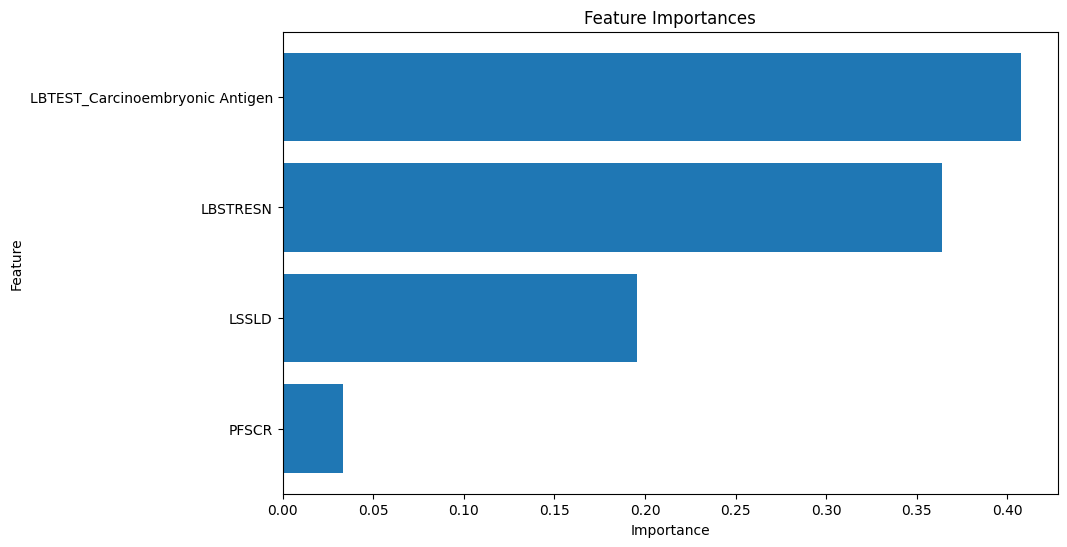

In [110]:
importances = model.feature_importances_


feature_names = X_train.columns

# Create a DataFrame for feature importances
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_importance_df)

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importances')
plt.gca().invert_yaxis()
plt.show()

## RandomizedSearchCV for RF

In [114]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the parameter grid for RandomizedSearchCV
param_distributions = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize the RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=100, 
    cv=5,       
    verbose=2,  
    random_state=42,
    n_jobs=-1 
)

# Fit RandomizedSearchCV
random_search.fit(X_train, y_train)


Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'max_depth': [None, 10, 20, 30],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [50, 100, 200, 300]},
                   random_state=42, verbose=2)

Accuracy: 0.9005714285714286
Classification Report:
               precision    recall  f1-score   support

         0.0       0.92      0.97      0.94       726
         1.0       0.79      0.57      0.66       149

    accuracy                           0.90       875
   macro avg       0.85      0.77      0.80       875
weighted avg       0.89      0.90      0.89       875

                           Feature  Importance
3  LBTEST_Carcinoembryonic Antigen    0.391912
2                         LBSTRESN    0.391662
1                            LSSLD    0.174480
0                            PFSCR    0.041946


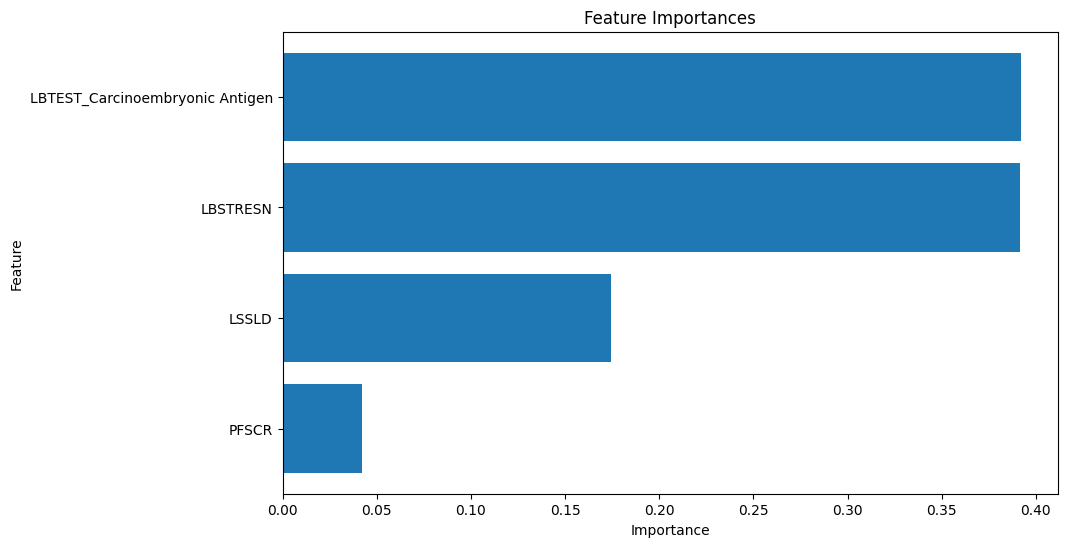

In [115]:
import pandas as pd
import matplotlib.pyplot as plt


best_model = random_search.best_estimator_

# Predict and evaluate
y_pred = best_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


importances = best_model.feature_importances_


feature_names = X_train.columns

# Create a DataFrame for feature importances
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_importance_df)

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importances')
plt.gca().invert_yaxis()

plt.show()